# Diabetes Risk Prediction — Model Evaluation & Comparative Study

**Academic Machine Learning Exam Project**  
**Phase 4:** Evaluation & Comparison of 5 Machine Learning Algorithms (Logistic Regression, KNN, Decision Tree, Random Forest, Gradient Boosting).

---

## 1. Import Evaluation Libraries & Load Test Data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
)

# Load Data
data_path = 'data/cleaned_diabetes.csv' if os.path.exists('data/cleaned_diabetes.csv') else '../data/cleaned_diabetes.csv'
df = pd.read_csv(data_path)

X = df.drop(columns=['Outcome'])
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Load Scaler
models_dir = 'models' if os.path.exists('models') else '../models'
scaler = joblib.load(os.path.join(models_dir, 'scaler.pkl'))
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Test Dataset size: {len(X_test)} samples")

Test Dataset size: 154 samples


## 2. Evaluate All 5 Trained Models

In [6]:
model_files = [
    ("Logistic Regression", "logistic_regression.pkl", True),
    ("KNN", "knn.pkl", True),
    ("Decision Tree", "decision_tree.pkl", False),
    ("Random Forest", "random_forest.pkl", False),
    ("Gradient Boosting", "gradient_boosting.pkl", False)
]

results = []
confusion_mats = {}

for name, filename, use_scaled in model_files:
    clf = joblib.load(os.path.join(models_dir, filename))
    X_te = X_test_scaled if use_scaled else X_test
    
    preds = clf.predict(X_te)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1 Score": round(f1, 4)
    })
    confusion_mats[name] = confusion_matrix(y_test, preds)

model_comparison = pd.DataFrame(results)
model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455
1,KNN,0.7532,0.6600,0.6111,0.6346
2,Decision Tree,0.6818,0.5532,0.4815,0.5149
3,Random Forest,0.7792,0.7273,0.5926,0.6531
4,Gradient Boosting,0.7597,0.6889,0.5741,0.6263


## 3. Metric Comparison Visualizations

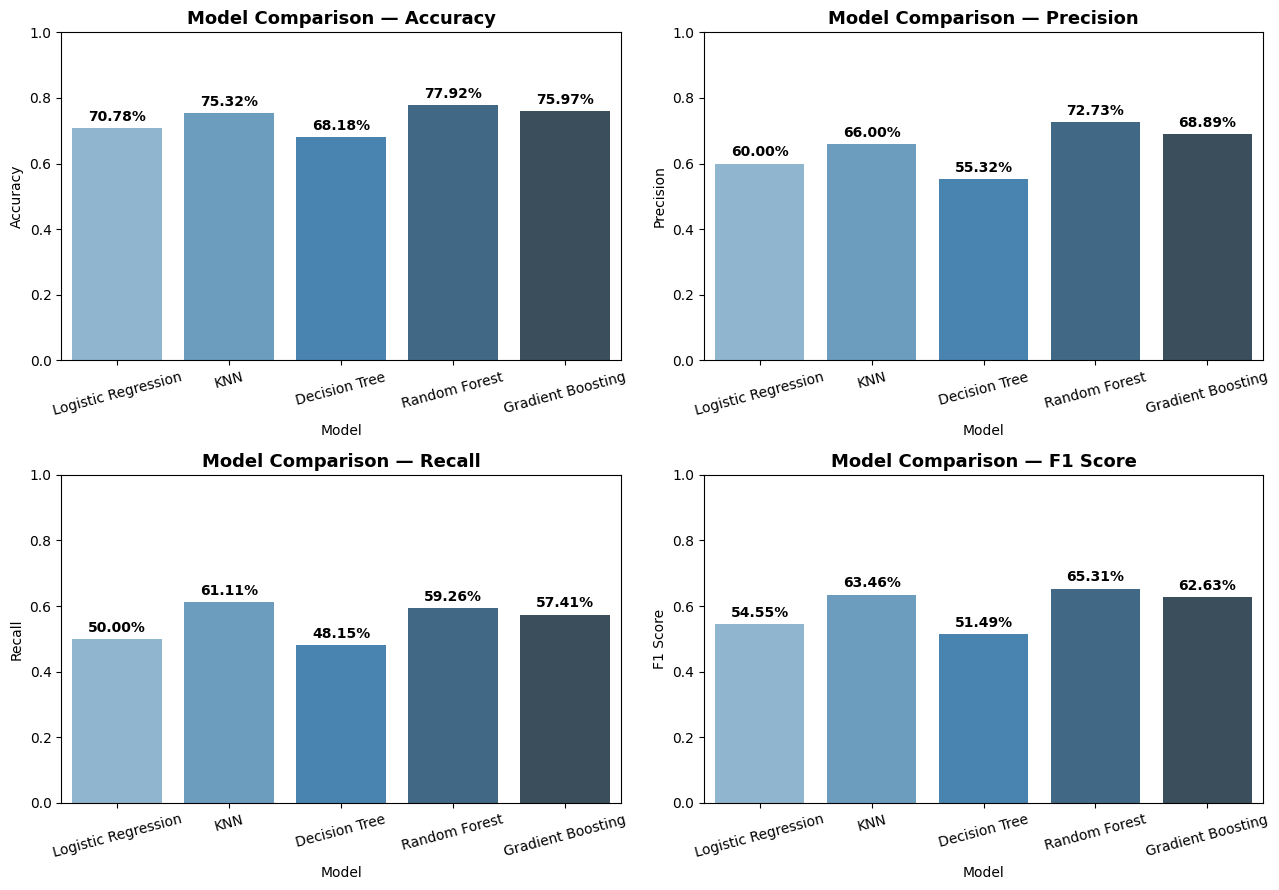

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for idx, m in enumerate(metrics):
    ax = axes[idx]
    sns.barplot(x="Model", y=m, data=model_comparison, ax=ax, hue="Model", palette="Blues_d", legend=False)
    ax.set_title(f"Model Comparison — {m}", fontsize=13, fontweight="bold")
    ax.set_ylim(0, 1.0)
    ax.tick_params(axis='x', rotation=15)
    
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

## 4. Confusion Matrices for All 5 Models

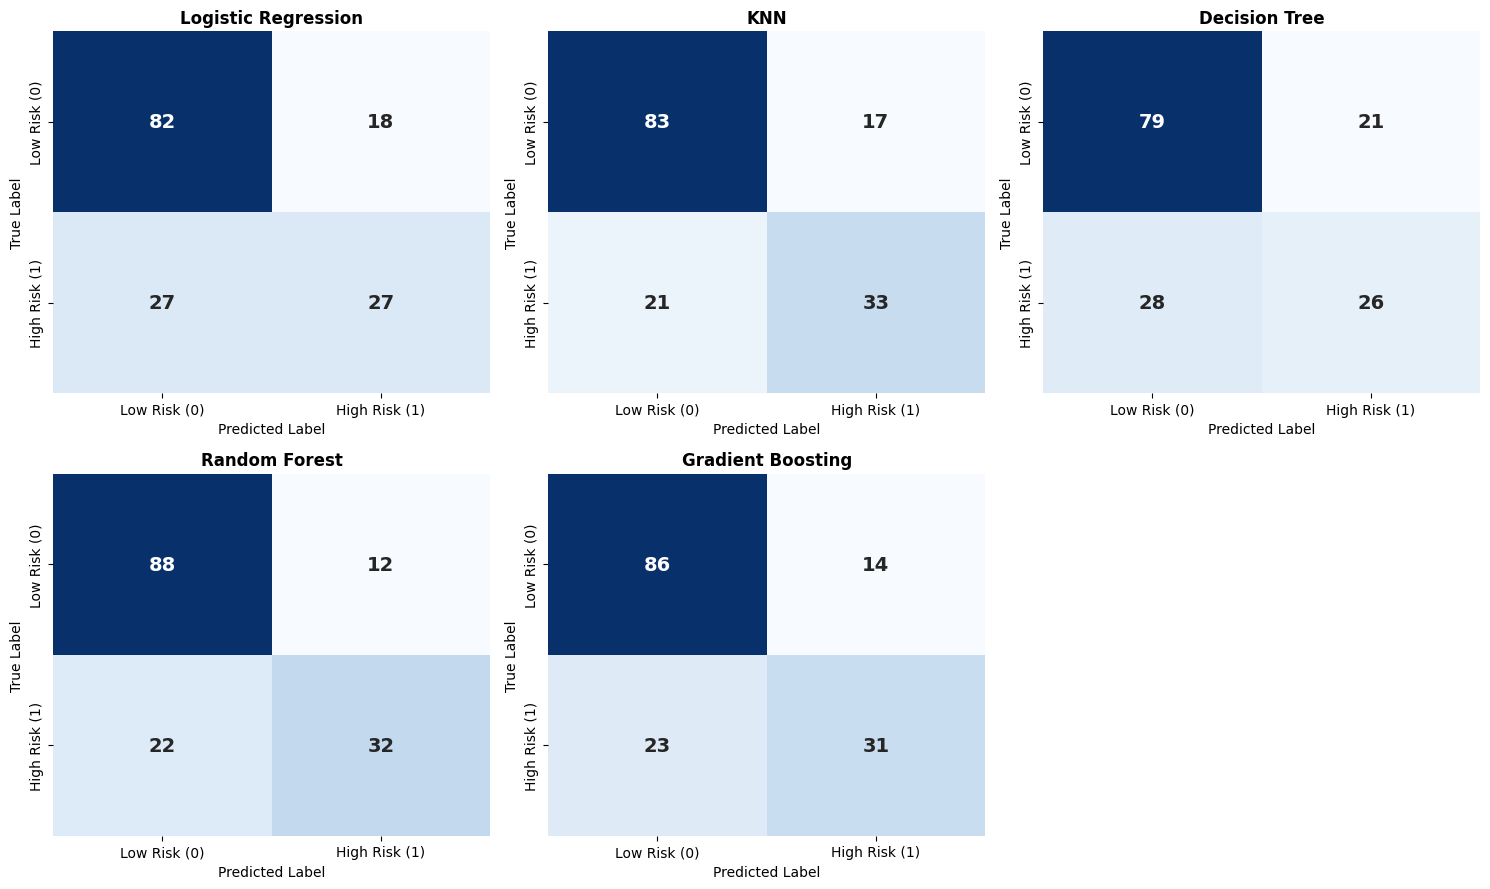

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, (name, _, _) in enumerate(model_files):
    ax = axes[idx]
    sns.heatmap(confusion_mats[name], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                annot_kws={"size": 14, "weight": "bold"})
    ax.set_title(f"{name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_xticklabels(["Low Risk (0)", "High Risk (1)"])
    ax.set_yticklabels(["Low Risk (0)", "High Risk (1)"])

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

## 5. Answers to Exam Evaluation Questions

### 📌 Medical Screening Context — Special Focus on RECALL:
- **Recall Definition:** Out of all patients who actually belong to the high-risk class, how many did the model correctly identify?
- **Clinical Rationale:** In screening applications, missing a high-risk patient (**False Negative**) can delay medical intervention. A **False Positive** merely leads to harmless secondary confirmation testing.
- **Educational Scope:** This tool is designed for educational/screening-support purposes, NOT as a diagnostic replacement.

--- 

### Answers based on actual dataset results:
1. **Can diabetes risk be predicted from patient characteristics?**  
   Yes, clinical attributes (Glucose, BMI, Age) provide strong signals, yielding up to **77.92%** test accuracy.

2. **Which features appear important?**  
   **Glucose**, **BMI**, and **Age** exhibit the highest predictive power.

3. **How do the five algorithms compare?**  
   - **Random Forest:** Best overall accuracy (**77.92%**) and F1-score (**65.31%**).
   - **KNN:** Best Recall (**61.11%**).
   - **Gradient Boosting:** Balanced performance (**75.97%** accuracy, **57.41%** recall).
   - **Logistic Regression:** Clean linear baseline (**70.78%** accuracy).
   - **Decision Tree:** Overfits training data, achieving lower test accuracy (**68.18%**).

4. **Which model has the highest recall?**  
   **K-Nearest Neighbors (KNN)** achieved the highest Recall (**61.11%**).

5. **How well can the models identify positive cases?**  
   Recall scores range between **48.15%** and **61.11%** across models.

6. **How well do models perform on unseen test data?**  
   Accuracies range from **68.18%** to **77.92%** on the test set.

7. **Does the model show signs of overfitting?**  
   Single Decision Tree exhibits overfitting (100% training accuracy vs 68.18% test accuracy). Ensemble methods generalize much better.

8. **Is the model suitable as a screening-support application?**  
   Yes, as a preliminary non-invasive risk flag for physician review.

9. **What are the limitations?**  
   Sample size (768 rows), moderate class imbalance, and demographic restriction to Pima Indian females.